<a href="https://colab.research.google.com/github/prosperowunna/mental-health-treatment-prediction/blob/main/mental_health_treatment_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows, columns: (1259, 27)
treatment
Yes    637
No     622
Name: count, dtype: int64
Best decision tree settings: {'max_depth': 4, 'min_samples_leaf': 10}


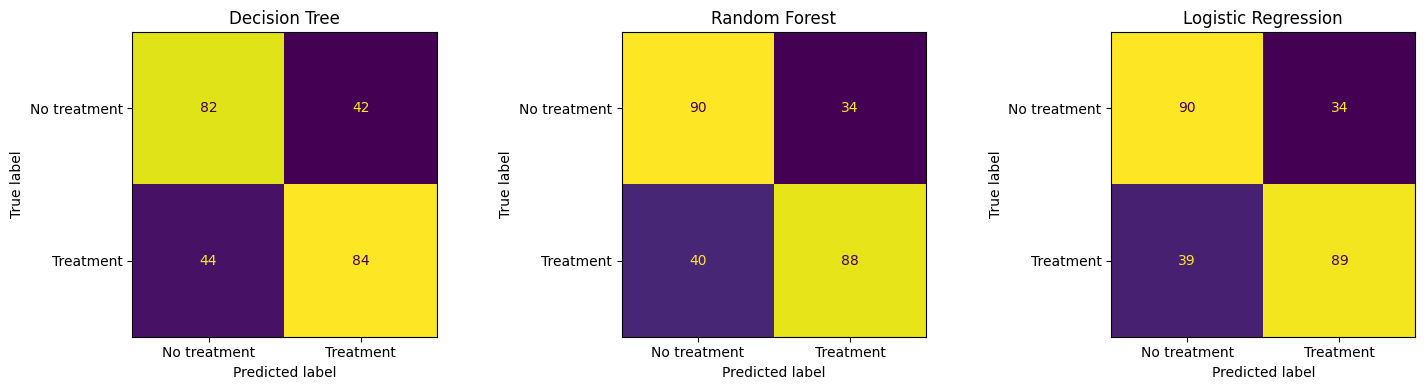

                     Accuracy  Precision  Recall     F1
Model                                                  
Decision Tree           0.659      0.667   0.656  0.661
Random Forest           0.706      0.721   0.688  0.704
Logistic Regression     0.710      0.724   0.695  0.709


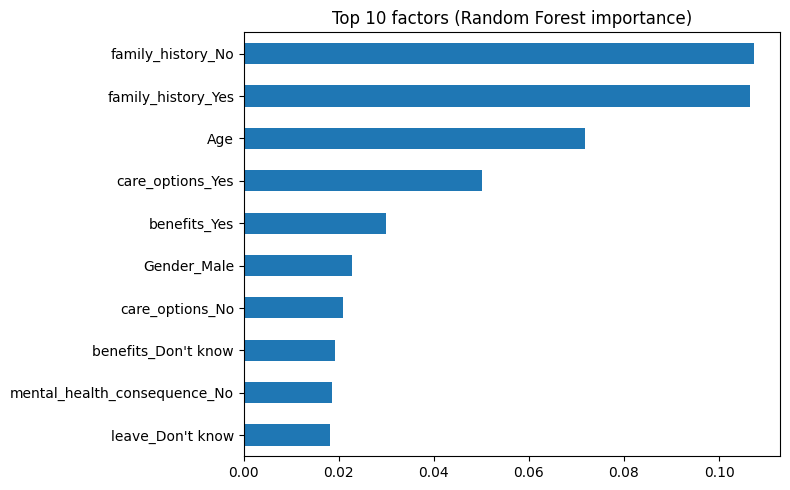

family_history_No               0.107460
family_history_Yes              0.106449
Age                             0.071887
care_options_Yes                0.050030
benefits_Yes                    0.029927
Gender_Male                     0.022660
care_options_No                 0.020970
benefits_Don't know             0.019099
mental_health_consequence_No    0.018579
leave_Don't know                0.018227
dtype: float64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
RANDOM_STATE = 42

# ---- 1. Load ----
df = pd.read_csv(path + "/survey.csv")
print("Rows, columns:", df.shape)
print(df["treatment"].value_counts())

# ---- 2. Clean ----
df.loc[(df["Age"] < 18) | (df["Age"] > 75), "Age"] = np.nan
df["Age"] = df["Age"].fillna(df["Age"].median())

def clean_gender(g):
    g = str(g).strip().lower()
    male = {"male","m","man","cis male","male (cis)","cis man","make","mal","msle","mail","malr","maile","male-ish"}
    female = {"female","f","woman","cis female","female (cis)","cis-female/femme","femake","femail","femme"}
    return "Male" if g in male else "Female" if g in female else "Other"
df["Gender"] = df["Gender"].apply(clean_gender)

# ---- 3. Features (drop work_interfere to avoid data leakage) ----
data = df.drop(columns=["Timestamp", "comments", "Country", "state", "work_interfere"])
y = (data.pop("treatment") == "Yes").astype(int)
X = pd.get_dummies(data.fillna("Unknown"))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# ---- 4. Train ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"max_depth": [2,3,4,5,6,8,10,None], "min_samples_leaf": [1,5,10,20]}, cv=cv, scoring="accuracy")
tree_search.fit(X_train, y_train)
print("Best decision tree settings:", tree_search.best_params_)
models = {
    "Decision Tree": tree_search.best_estimator_,
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE).fit(X_train, y_train),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train),
}

# ---- 5. Evaluate ----
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No treatment", "Treatment"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
results = pd.DataFrame(rows).set_index("Model").round(3)
print(results)

# ---- 6. Top factors ----
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp[::-1].plot(kind="barh", figsize=(8, 5), title="Top 10 factors (Random Forest importance)")
plt.tight_layout(); plt.show()
print(imp)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("osmi/mental-health-in-tech-survey")

print("Path to dataset files:", path)

100%|██████████| 48.8k/48.8k [00:00<00:00, 42.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/osmi/mental-health-in-tech-survey/versions/3
